# Esercitazione finale · Modulo 4
## ToysGroup: analisi dei dati di vendita

In questo notebook svolgo tutti i task della traccia, uno dopo l'altro. Prima di ogni cella di codice scrivo il numero del task e la risposta.

I file che uso (devono stare nella stessa cartella del notebook): `products.csv`, `regions.xlsx`, `sales.json`, `resellers.csv`.

### Task 0 · Librerie
Importo le librerie che servono in tutto il notebook.

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, roc_auc_score
from sklearn.cluster import KMeans

---
# Task 1 · Python di base

In questo task Pandas lo uso **solo per leggere i file**. Somme, conteggi e fasce di prezzo li faccio con Python normale (liste, dizionari, cicli, funzioni).

### Task 1.1 · Lettura dei file e strutture dati
**Cosa chiede**: leggere `products.csv` e `sales.json` e trasformarli in liste di dizionari con `.to_dict(orient="records")`; costruire `regions` come dizionario `{RegionID: (State, SalesRegion)}` e il set delle categorie.

In [2]:
# products e sales: una lista, dove ogni riga è un dizionario
prodotti = pd.read_csv("products.csv").to_dict(orient="records")
vendite = pd.read_json("sales.json").to_dict(orient="records")

# regions: dizionario {RegionID: (State, SalesRegion)}
tabella_regioni = pd.read_excel("regions.xlsx").to_dict(orient="records")
regions = {}
for r in tabella_regioni:
    regions[r["RegionID"]] = (r["State"], r["SalesRegion"])

# set delle categorie (il set non tiene i doppioni)
categorie = set()
for p in prodotti:
    categorie.add(p["Category"])

print("Numero di prodotti:", len(prodotti))
print("Dizionario regions:", regions)
print("Set delle categorie:", categorie)

Numero di prodotti: 12
Dizionario regions: {1: ('Italia', 'Sud Europa'), 2: ('Francia', 'Sud Europa'), 3: ('Spagna', 'Sud Europa'), 4: ('Germania', 'Centro Europa'), 5: ('Austria', 'Centro Europa'), 6: ('Svizzera', 'Centro Europa'), 7: ('Svezia', 'Nord Europa'), 8: ('Norvegia', 'Nord Europa'), 9: ('Danimarca', 'Nord Europa')}
Set delle categorie: {'Giochi da tavolo', 'Giocattoli', 'Outdoor'}


**Risposta 1.1**: ci sono **12 prodotti** (e 2000 vendite). Il dizionario `regions` ha 9 regioni, ognuna con la coppia (stato, regione di vendita). Le categorie sono **3**: Giocattoli, Giochi da tavolo, Outdoor.

### Task 1.2 · Fascia di prezzo
**Cosa chiede**: con una list comprehension e un `if/elif/else` dare a ogni prodotto la fascia di prezzo: Bassa sotto 20 €, Media fino a 60 €, Alta oltre.

L'`if/elif/else` lo metto in una funzione, e la list comprehension chiama la funzione per ogni prodotto.

In [3]:
def fascia_prezzo(prezzo):
    if prezzo < 20:
        return "Bassa"
    elif prezzo <= 60:
        return "Media"
    else:
        return "Alta"

# list comprehension: una fascia per ogni prodotto
fasce = [fascia_prezzo(p["ListPrice"]) for p in prodotti]

# aggiungo la fascia a ogni prodotto
for i in range(len(prodotti)):
    prodotti[i]["Fascia"] = fasce[i]
    print(prodotti[i]["ProductName"], "-", prodotti[i]["ListPrice"], "€ ->", prodotti[i]["Fascia"])

Bici Junior - 129.0 € -> Alta
Bici BMX - 189.0 € -> Alta
Monopattino - 79.0 € -> Alta
Pallone Calcio - 19.9 € -> Bassa
Racchette Beach - 14.5 € -> Bassa
Puzzle 1000 - 17.9 € -> Bassa
Gioco dell'Oca - 12.5 € -> Bassa
Scacchi Legno - 34.0 € -> Media
Costruzioni 500 - 39.9 € -> Media
Bambola Classica - 24.9 € -> Media
Robot RC - 89.0 € -> Alta
Macchinina RC - 59.0 € -> Media


**Risposta 1.2**: ogni prodotto ha la sua fascia. Bassa: 4 prodotti, Media: 4, Alta: 4.

### Task 1.3 · Funzione `fatturato_categoria`
**Cosa chiede**: una funzione `fatturato_categoria(vendite, prodotti, categoria)` che con un ciclo `for` somma `SalesAmount` della categoria, salta i valori mancanti e restituisce il totale con `return`. Il risultato va confrontato con il Task 3b.

In [4]:
def fatturato_categoria(vendite, prodotti, categoria):
    totale = 0
    for v in vendite:
        # se l'importo manca, salto la vendita
        if math.isnan(v["SalesAmount"]):
            continue
        # cerco il prodotto venduto e controllo la sua categoria
        for p in prodotti:
            if p["ProductID"] == v["ProductID"] and p["Category"] == categoria:
                totale = totale + v["SalesAmount"]
    return totale

fatturati_task1 = {}
for c in sorted(categorie):
    fatturati_task1[c] = fatturato_categoria(vendite, prodotti, c)
    print(c, "->", round(fatturati_task1[c], 2), "€")

Giocattoli -> 174832.0 €
Giochi da tavolo -> 53245.1 €
Outdoor -> 331998.4 €


**Risposta 1.3**: il fatturato per categoria è: Giocattoli 174.832,00 €; Giochi da tavolo 53.245,10 €; Outdoor 331.998,40 €. Lo confronto con il Task 3b più avanti.

### Task 1.4 · Ciclo `while`
**Cosa chiede**: con un ciclo `while` contare quante transazioni servono per superare 10.000 € di fatturato cumulato e mostrare le prime cinque con `vendite[:5]`.

Le vendite nel file sono già in ordine di data. Se una vendita non ha l'importo la salto e non la conto.

In [5]:
cumulato = 0
contate = 0
i = 0

while cumulato <= 10000:
    importo = vendite[i]["SalesAmount"]
    if not math.isnan(importo):
        cumulato = cumulato + importo
        contate = contate + 1
    i = i + 1

print("Transazioni necessarie:", contate)
print("Fatturato cumulato:", round(cumulato, 2), "€")
print()
print("Prime cinque transazioni:")
print(vendite[:5])

Transazioni necessarie: 52
Fatturato cumulato: 10164.8 €

Prime cinque transazioni:
[{'SalesID': 1194, 'ProductID': 6, 'RegionID': 7, 'ResellerID': 283, 'SalesDate': '2023-01-01', 'Quantity': 4.0, 'SalesAmount': 71.6}, {'SalesID': 859, 'ProductID': 6, 'RegionID': 8, 'ResellerID': 28, 'SalesDate': '2023-01-02', 'Quantity': 7.0, 'SalesAmount': nan}, {'SalesID': 1747, 'ProductID': 12, 'RegionID': 3, 'ResellerID': 281, 'SalesDate': '2023-01-02', 'Quantity': 2.0, 'SalesAmount': 118.0}, {'SalesID': 279, 'ProductID': 3, 'RegionID': 7, 'ResellerID': 128, 'SalesDate': '2023-01-02', 'Quantity': 3.0, 'SalesAmount': nan}, {'SalesID': 1470, 'ProductID': 1, 'RegionID': 6, 'ResellerID': 137, 'SalesDate': '2023-01-04', 'Quantity': 4.0, 'SalesAmount': nan}]


**Risposta 1.4**: servono **52 transazioni** per superare i 10.000 € (arrivo a 10.164,80 €).

### Definizione richiesta · lista, tupla, set, dizionario
| | Si può modificare? | Ordine | Duplicati | Come si accede |
|---|---|---|---|---|
| **Lista** `[1, 2]` | sì | ordinata | sì | con l'indice `l[0]` |
| **Tupla** `(1, 2)` | no | ordinata | sì | con l'indice `t[0]` |
| **Set** `{1, 2}` | sì | senza ordine | no | non ha indice né chiave, si controlla se un elemento c'è (`x in s`) |
| **Dizionario** `{"a": 1}` | sì | ordinato per inserimento | chiavi uniche, valori anche uguali | con la chiave `d["a"]` |

**Criterio di completamento**: ✔ `len()` dei prodotti, dizionario `regions` e set delle categorie · ✔ fascia di ogni prodotto · ✔ fatturato per categoria con `fatturato_categoria()`.

---
# Task 2 · Lettura e ispezione dei dati
Qui non modifico niente: guardo i dati e faccio delle selezioni.

### Task 2.1 · Lettura dei quattro file
**Cosa chiede**: leggere i file con `read_csv()`, `read_excel()` e `read_json()` e mostrare per ognuno `.shape`, `.info()`, `.head()` e `.tail()`.

In [6]:
products = pd.read_csv("products.csv")
regions_df = pd.read_excel("regions.xlsx")   # lo chiamo regions_df perché "regions" è il dizionario del Task 1
sales = pd.read_json("sales.json")
resellers = pd.read_csv("resellers.csv")

for nome, tabella in [("products", products), ("regions_df", regions_df), ("sales", sales), ("resellers", resellers)]:
    print("=====", nome, "=====")
    print("shape:", tabella.shape)
    tabella.info()
    display(tabella.head())
    display(tabella.tail())

===== products =====
shape: (12, 4)
<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   ProductID    12 non-null     int64  
 1   ProductName  12 non-null     str    
 2   Category     12 non-null     str    
 3   ListPrice    12 non-null     float64
dtypes: float64(1), int64(1), str(2)
memory usage: 516.0 bytes


,ProductID,ProductName,Category,ListPrice
0,1,Bici Junior,Outdoor,129.0
1,2,Bici BMX,Outdoor,189.0
2,3,Monopattino,Outdoor,79.0
3,4,Pallone Calcio,Outdoor,19.9
4,5,Racchette Beach,Outdoor,14.5


,ProductID,ProductName,Category,ListPrice
7,8,Scacchi Legno,Giochi da tavolo,34.0
8,9,Costruzioni 500,Giocattoli,39.9
9,10,Bambola Classica,Giocattoli,24.9
10,11,Robot RC,Giocattoli,89.0
11,12,Macchinina RC,Giocattoli,59.0


===== regions_df =====
shape: (9, 3)
<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   RegionID     9 non-null      int64
 1   State        9 non-null      str  
 2   SalesRegion  9 non-null      str  
dtypes: int64(1), str(2)
memory usage: 348.0 bytes


,RegionID,State,SalesRegion
0,1,Italia,Sud Europa
1,2,Francia,Sud Europa
2,3,Spagna,Sud Europa
3,4,Germania,Centro Europa
4,5,Austria,Centro Europa


,RegionID,State,SalesRegion
4,5,Austria,Centro Europa
5,6,Svizzera,Centro Europa
6,7,Svezia,Nord Europa
7,8,Norvegia,Nord Europa
8,9,Danimarca,Nord Europa


===== sales =====
shape: (2000, 7)
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   SalesID      2000 non-null   int64  
 1   ProductID    2000 non-null   int64  
 2   RegionID     2000 non-null   int64  
 3   ResellerID   2000 non-null   int64  
 4   SalesDate    2000 non-null   str    
 5   Quantity     1900 non-null   float64
 6   SalesAmount  1900 non-null   float64
dtypes: float64(2), int64(4), str(1)
memory usage: 109.5 KB


,SalesID,ProductID,RegionID,ResellerID,SalesDate,Quantity,SalesAmount
0,1194,6,7,283,2023-01-01,4.0,71.6
1,859,6,8,28,2023-01-02,7.0,NaN
2,1747,12,3,281,2023-01-02,2.0,118.0
3,279,3,7,128,2023-01-02,3.0,NaN
4,1470,1,6,137,2023-01-04,4.0,NaN


,SalesID,ProductID,RegionID,ResellerID,SalesDate,Quantity,SalesAmount
1995,326,3,1,280,2025-12-27,4.0,316.0
1996,394,7,2,256,2025-12-29,5.0,62.5
1997,196,4,8,50,2025-12-29,5.0,99.5
1998,878,4,4,27,2025-12-30,8.0,159.2
1999,1278,9,5,57,2025-12-30,9.0,359.1


===== resellers =====
shape: (300, 7)
<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ResellerID          300 non-null    int64  
 1   RegionID            300 non-null    int64  
 2   Ordini12m           300 non-null    int64  
 3   GiorniUltimoOrdine  300 non-null    int64  
 4   ScontoMedio         300 non-null    float64
 5   Reclami             300 non-null    int64  
 6   Churn               300 non-null    int64  
dtypes: float64(1), int64(6)
memory usage: 16.5 KB


,ResellerID,RegionID,Ordini12m,GiorniUltimoOrdine,ScontoMedio,Reclami,Churn
0,1,1,14,65,0.131,1,0
1,2,7,9,149,0.117,1,0
2,3,6,21,1,0.065,2,0
3,4,4,18,162,0.011,1,1
4,5,4,22,98,0.120,0,0


,ResellerID,RegionID,Ordini12m,GiorniUltimoOrdine,ScontoMedio,Reclami,Churn
295,296,5,18,145,0.218,1,0
296,297,8,17,104,0.048,0,0
297,298,4,16,141,0.055,2,0
298,299,3,13,113,0.164,0,0
299,300,1,12,116,0.072,0,0


**Risposta 2.1**:

| Tabella | Righe | Colonne | Non nulli |
|---|---|---|---|
| `products` | 12 | 4 | tutte complete |
| `regions_df` | 9 | 3 | tutte complete |
| `sales` | 2000 | 7 | `Quantity` e `SalesAmount` hanno solo 1900 valori su 2000 |
| `resellers` | 300 | 7 | tutte complete |

I tipi sono quelli che si vedono in `.info()`: numeri interi e decimali, e testo. `SalesDate` per ora è ancora testo.

### Task 2.2 · `describe()` e prezzo unitario con NumPy
**Cosa chiede**: con `.describe()` trovare minimo, massimo e media di `Quantity` e `SalesAmount`; poi trasformare le due colonne in array NumPy e calcolare il prezzo unitario di ogni vendita con un'operazione vettoriale.

In [7]:
statistiche = sales[["Quantity", "SalesAmount"]].describe()
print(statistiche)

# da colonne Pandas ad array NumPy
quantita = sales["Quantity"].to_numpy()
importi = sales["SalesAmount"].to_numpy()

# prezzo unitario = importo / quantità, per tutte le vendite in un colpo solo
prezzo_unitario = importi / quantita

print()
print("Primi 10 prezzi unitari:", prezzo_unitario[:10])

          Quantity  SalesAmount
count  1900.000000  1900.000000
mean      4.966316   294.776579
std       2.206535   305.261212
min       1.000000    12.500000
25%       3.000000    89.000000
50%       5.000000   177.000000
75%       6.000000   387.000000
max      14.000000  2457.000000

Primi 10 prezzi unitari: [17.9  nan 59.   nan  nan 12.5 79.  79.  12.5  nan]


**Risposta 2.2**:
- `Quantity`: minimo **1**, massimo **14**, media **4,97**.
- `SalesAmount`: minimo **12,50 €**, massimo **2.457,00 €**, media **294,78 €**.
- Il prezzo unitario viene calcolato per tutte le vendite insieme. Dove manca la quantità o l'importo il risultato è `NaN`.

### Task 2.3 · `.loc[]` e `.iloc[]`
**Cosa chiede**: con `.loc[]` e una maschera booleana i prodotti di una categoria con `ListPrice` sopra 30 €; con `.iloc[]` le righe da 10 a 19 e le prime tre colonne di `sales`.

In [8]:
# .loc con maschera booleana: categoria Outdoor e prezzo maggiore di 30
maschera = (products["Category"] == "Outdoor") & (products["ListPrice"] > 30)
prodotti_cari = products.loc[maschera]
display(prodotti_cari)

# .iloc: righe da 10 a 19 (la 20 non entra) e prime tre colonne
selezione = sales.iloc[10:20, 0:3]
display(selezione)
print("Forma della selezione:", selezione.shape)

,ProductID,ProductName,Category,ListPrice
0,1,Bici Junior,Outdoor,129.0
1,2,Bici BMX,Outdoor,189.0
2,3,Monopattino,Outdoor,79.0


,SalesID,ProductID,RegionID
10,218,1,8
11,1136,1,9
12,1326,3,4
13,1063,9,7
14,1606,10,8
15,1283,12,1
16,98,3,4
17,156,6,8
18,1642,12,5
19,1644,4,7


Forma della selezione: (10, 3)


**Risposta 2.3**: nella categoria Outdoor i prodotti sopra i 30 € sono **3** (Bici Junior, Bici BMX, Monopattino). La selezione con `.iloc[]` ha **10 righe e 3 colonne**, come richiesto.

### Definizione richiesta · Series/DataFrame e `.loc[]`/`.iloc[]`
- Una **Series** è una colonna sola (una dimensione). Un **DataFrame** è una tabella con righe e colonne (due dimensioni).
- **`.loc[]`** sceglie righe e colonne per **etichetta** (il nome) o con una maschera di True/False. **`.iloc[]`** le sceglie per **posizione** (0, 1, 2...) e l'ultimo numero dello slice è escluso.

**Criterio di completamento**: ✔ righe, colonne, tipi e non nulli di ogni tabella · ✔ la selezione con `.iloc[]` ha 10 righe e 3 colonne.

---
# Task 3a · Dati mancanti, filtri e ordinamento
Da qui lavoro su una copia di `sales` che chiamo `sales_pulito`, così l'originale resta intatto.

### Task 3a.1 · Contare i NaN
**Cosa chiede**: contare i NaN per colonna con `.isna().sum()` e calcolare la percentuale sul totale delle righe.

In [9]:
nan_per_colonna = sales.isna().sum()
percentuale = nan_per_colonna / len(sales) * 100

tabella_nan = pd.DataFrame({"NaN": nan_per_colonna, "Percentuale %": percentuale})
display(tabella_nan)

,NaN,Percentuale %
SalesID,0,0.0
ProductID,0,0.0
RegionID,0,0.0
ResellerID,0,0.0
SalesDate,0,0.0
Quantity,100,5.0
SalesAmount,100,5.0


**Risposta 3a.1**: i valori mancanti sono solo in due colonne: `Quantity` ha **100 NaN (5,0%)** e `SalesAmount` ha **100 NaN (5,0%)**, su 2000 righe.

### Task 3a.2 · Riempire `Quantity` ed eliminare i `SalesAmount` mancanti
**Cosa chiede**: riempire `Quantity` con la mediana usando `fillna()`, eliminare con `dropna()` le righe con `SalesAmount` mancante e dire quante righe ho tolto.

Attenzione: la mediana la calcolo **prima** del `fillna()`, sui valori presenti.

In [10]:
sales_pulito = sales.copy()

# Quantity: mediana calcolata prima, poi fillna
mediana = sales_pulito["Quantity"].median()
sales_pulito["Quantity"] = sales_pulito["Quantity"].fillna(mediana)

# SalesAmount: tolgo le righe senza importo
righe_prima = len(sales_pulito)
sales_pulito = sales_pulito.dropna(subset=["SalesAmount"])
righe_rimosse = righe_prima - len(sales_pulito)

print("Mediana di Quantity:", mediana)
print("Righe rimosse:", righe_rimosse)

# tabella dei NaN prima e dopo
tabella_prima_dopo = pd.DataFrame({"NaN prima": sales.isna().sum(), "NaN dopo": sales_pulito.isna().sum()})
display(tabella_prima_dopo)

Mediana di Quantity: 5.0
Righe rimosse: 100


,NaN prima,NaN dopo
SalesID,0,0
ProductID,0,0
RegionID,0,0
ResellerID,0,0
SalesDate,0,0
Quantity,100,0
SalesAmount,100,0


**Risposta 3a.2**: ho riempito i NaN di `Quantity` con la mediana, che è **5**: dopo il `fillna()`, `.isna().sum()` di `Quantity` fa 0. Poi ho eliminato **100 righe** per `SalesAmount` mancante, quindi `sales_pulito` ha 1900 righe (prima erano 2000).

### Task 3a.3 · Filtro con `.query()` e ordinamento
**Cosa chiede**: con `.query()` prendere le transazioni con `SalesAmount` sopra il 90° percentile (`quantile(0.9)`) e ordinarle con `sort_values()` per data crescente e importo decrescente.

In [11]:
soglia = sales_pulito["SalesAmount"].quantile(0.9)

transazioni_alte = sales_pulito.query("SalesAmount > @soglia")
transazioni_alte = transazioni_alte.sort_values(["SalesDate", "SalesAmount"], ascending=[True, False])

print("90° percentile:", soglia)
print("Numero di transazioni sopra la soglia:", len(transazioni_alte))
transazioni_alte.head(10)

90° percentile: 756.0
Numero di transazioni sopra la soglia: 162


,SalesID,ProductID,RegionID,ResellerID,SalesDate,Quantity,SalesAmount
32,1045,2,4,82,2023-01-16,6.0,1134.0
49,1872,2,7,204,2023-01-25,5.0,945.0
52,1639,1,3,299,2023-01-27,9.0,1161.0
102,296,2,9,202,2023-02-25,5.0,945.0
118,1462,2,2,224,2023-03-03,5.0,945.0
121,1221,1,8,149,2023-03-05,8.0,1032.0
123,1753,2,8,151,2023-03-05,5.0,945.0
168,283,2,2,100,2023-03-30,11.0,2079.0
217,1679,1,4,22,2023-04-27,5.0,774.0
221,832,2,4,82,2023-04-28,6.0,1134.0


**Risposta 3a.3**: il 90° percentile di `SalesAmount` è **756,00 €** e le transazioni sopra questa soglia sono **162**. Le ho ordinate per data crescente e, a parità di data, per importo decrescente. Il controllo con `.head(10)` è nella cella qui sopra.

### Definizione richiesta · imputazione dei dati mancanti
**Imputare** vuol dire riempire un valore mancante con un valore ragionevole, invece di buttare la riga.
- **Media**: va bene se i dati sono "regolari", ma si fa spostare dai valori molto grandi o molto piccoli.
- **Mediana**: è più sicura se ci sono valori anomali, perché non si sposta. Con la media e la mediana la distribuzione si "schiaccia" un po' verso il centro, perché metto tanti valori uguali.
- **Eliminare la riga** (`dropna()`): non inventa niente, ma perdo dati. Lo uso quando il valore mancante è proprio quello che devo analizzare: per questo l'ho fatto per `SalesAmount` e non per `Quantity`.

**Criterio di completamento**: ✔ tabella dei NaN prima e dopo · ✔ righe eliminate: **100** · ✔ filtro e ordinamento verificati con `.head(10)`.

---
# Task 3b · Aggregazioni e unione delle tabelle

### Task 3b.1 · `merge()`
**Cosa chiede**: unire `sales` con `products` e `regions` con `merge()` su `ProductID` e `RegionID` (`how="left"`) e controllare che le righe restino quelle di `sales`.

In [12]:
df = sales_pulito.merge(products, on="ProductID", how="left")
df = df.merge(regions_df, on="RegionID", how="left")

print("Righe di sales_pulito:", len(sales_pulito))
print("Righe dopo il merge:  ", len(df))
print()
print("NaN dopo il merge:")
print(df.isna().sum())

df.head()

Righe di sales_pulito: 1900
Righe dopo il merge:   1900

NaN dopo il merge:
SalesID        0
ProductID      0
RegionID       0
ResellerID     0
SalesDate      0
Quantity       0
SalesAmount    0
ProductName    0
Category       0
ListPrice      0
State          0
SalesRegion    0
dtype: int64


,SalesID,ProductID,RegionID,ResellerID,SalesDate,Quantity,SalesAmount,ProductName,Category,ListPrice,State,SalesRegion
0,1194,6,7,283,2023-01-01,4.0,71.6,Puzzle 1000,Giochi da tavolo,17.9,Svezia,Nord Europa
1,1747,12,3,281,2023-01-02,2.0,118.0,Macchinina RC,Giocattoli,59.0,Spagna,Sud Europa
2,947,7,8,166,2023-01-04,6.0,75.0,Gioco dell'Oca,Giochi da tavolo,12.5,Norvegia,Nord Europa
3,577,3,4,285,2023-01-04,3.0,237.0,Monopattino,Outdoor,79.0,Germania,Centro Europa
4,78,3,8,107,2023-01-04,3.0,237.0,Monopattino,Outdoor,79.0,Norvegia,Nord Europa


**Risposta 3b.1**: dopo i due `merge()` ho **1900 righe**, le stesse di `sales_pulito` (1900). Nelle colonne arrivate da `products` e `regions` non ci sono NaN, quindi ogni vendita ha trovato il suo prodotto e la sua regione.

### Task 3b.2 · `groupby()` e `agg()`
**Cosa chiede**: fatturato totale, quantità totale e numero di transazioni per `Category` e per `SalesRegion`, in ordine di fatturato decrescente.

In [13]:
per_categoria = df.groupby("Category").agg(
    Fatturato=("SalesAmount", "sum"),
    Quantita=("Quantity", "sum"),
    Transazioni=("SalesID", "count"),
)
per_categoria = per_categoria.sort_values("Fatturato", ascending=False)

per_regione = df.groupby("SalesRegion").agg(
    Fatturato=("SalesAmount", "sum"),
    Quantita=("Quantity", "sum"),
    Transazioni=("SalesID", "count"),
)
per_regione = per_regione.sort_values("Fatturato", ascending=False)

display(per_categoria)
display(per_regione)

# confronto con il Task 1.3
print("Confronto con il Task 1.3:")
for c in per_categoria.index:
    print(c, "| Pandas:", round(per_categoria.loc[c, "Fatturato"], 2), "| Task 1:", round(fatturati_task1[c], 2))

,Fatturato,Quantita,Transazioni
Category,,,
Outdoor,331998.4,3800.0,767
Giocattoli,174832.0,3225.0,644
Giochi da tavolo,53245.1,2416.0,489


,Fatturato,Quantita,Transazioni
SalesRegion,,,
Centro Europa,201062.2,3413.0,698
Nord Europa,190189.0,3175.0,633
Sud Europa,168824.3,2853.0,569


Confronto con il Task 1.3:
Outdoor | Pandas: 331998.4 | Task 1: 331998.4
Giocattoli | Pandas: 174832.0 | Task 1: 174832.0
Giochi da tavolo | Pandas: 53245.1 | Task 1: 53245.1


**Risposta 3b.2**: la **categoria con il fatturato più alto è Outdoor** (331.998,40 €), poi Giocattoli (174.832,00 €) e Giochi da tavolo (53.245,10 €). Tra le regioni di vendita la prima è **Centro Europa** (201.062,20 €).

**Confronto con il Task 1.3**: i fatturati per categoria calcolati con i cicli e quelli calcolati con `groupby()` sono **uguali** (si vede dalla stampa qui sopra).

### Task 3b.3 · Separare il 2025 e rimettere insieme con `concat()`
**Cosa chiede**: separare le vendite del 2025 dalle altre con un filtro, rimetterle insieme con `pd.concat()` e controllare che le righe coincidano con l'originale.

In [14]:
anno = pd.to_datetime(df["SalesDate"]).dt.year

vendite_2025 = df[anno == 2025]
vendite_altre = df[anno != 2025]

rimesse_insieme = pd.concat([vendite_altre, vendite_2025])

print("Vendite 2025:", len(vendite_2025))
print("Altre vendite:", len(vendite_altre))
print("Somma:", len(vendite_2025) + len(vendite_altre))
print("Righe dell'originale:", len(df))
print("Righe dopo il concat:", len(rimesse_insieme))

Vendite 2025: 640
Altre vendite: 1260
Somma: 1900
Righe dell'originale: 1900
Righe dopo il concat: 1900


**Risposta 3b.3**: le vendite del 2025 sono **640** e le altre **1260**. 640 + 1260 = **1900**, cioè le righe dell'originale. Anche dopo il `concat()` le righe sono 1900: è tutto a posto.

### Definizione richiesta · `merge()`, `join()`, `concat()`
- **`merge()`**: unisce due tabelle usando una **colonna chiave** in comune (come il JOIN di SQL).
- **`join()`**: unisce due tabelle usando l'**indice**.
- **`concat()`**: non cerca corrispondenze, **mette le tabelle una sotto l'altra** (righe) o una accanto all'altra (colonne).

**Da ricordare**: con `how="inner"` il merge scarta le vendite senza corrispondenza in `products` o `regions`; con `how="left"` le tiene con NaN, che si contano con `.isna().sum()`. Qui i NaN sono 0.

**Criterio di completamento**: ✔ righe dopo il merge uguali a `sales_pulito` · ✔ due tabelle aggregate · ✔ categoria con il fatturato più alto: **Outdoor**.

---
# Task 3c · Serie temporali

### Task 3c.1 · Convertire `SalesDate`
**Cosa chiede**: convertire `SalesDate` con `pd.to_datetime()` e controllare il tipo con `.dtypes`.

In [15]:
df["SalesDate"] = pd.to_datetime(df["SalesDate"])
print(df.dtypes)

SalesID                 int64
ProductID               int64
RegionID                int64
ResellerID              int64
SalesDate      datetime64[us]
Quantity              float64
SalesAmount           float64
ProductName               str
Category                  str
ListPrice             float64
State                     str
SalesRegion               str
dtype: object


**Risposta 3c.1**: ora `SalesDate` è di tipo **datetime64[us]**, cioè una vera data (`datetime64`) e non più testo.

### Task 3c.2 · Anno, mese e giorno della settimana
**Cosa chiede**: con `.dt` creare tre nuove colonne con anno, mese e giorno della settimana.

In [16]:
df["Anno"] = df["SalesDate"].dt.year
df["Mese"] = df["SalesDate"].dt.month
df["GiornoSettimana"] = df["SalesDate"].dt.dayofweek   # 0 = lunedì, 6 = domenica

df[["SalesDate", "Anno", "Mese", "GiornoSettimana"]].head()

,SalesDate,Anno,Mese,GiornoSettimana
0,2023-01-01,2023,1,6
1,2023-01-02,2023,1,0
2,2023-01-04,2023,1,2
3,2023-01-04,2023,1,2
4,2023-01-04,2023,1,2


**Risposta 3c.2**: ho creato `Anno`, `Mese` e `GiornoSettimana` (0 = lunedì, 6 = domenica) con `.dt.year`, `.dt.month` e `.dt.dayofweek`. Le vendite vanno dal 01/01/2023 al 30/12/2025.

### Task 3c.3 · Fatturato mensile e variazione percentuale
**Cosa chiede**: calcolare il fatturato mensile con `groupby()` su anno e mese, e la variazione percentuale tra mesi consecutivi con `pct_change()`.

In [17]:
fatturato_mensile = df.groupby(["Anno", "Mese"])["SalesAmount"].sum()
variazione = fatturato_mensile.pct_change() * 100

mensile = pd.DataFrame({"Fatturato": fatturato_mensile, "Variazione %": variazione.round(1)})
mensile = mensile.reset_index()

print("Righe della serie mensile:", len(mensile))

# mese con il fatturato massimo
riga_massimo = mensile["Fatturato"].idxmax()
anno_picco = mensile.loc[riga_massimo, "Anno"]
mese_picco = mensile.loc[riga_massimo, "Mese"]
fatturato_picco = mensile.loc[riga_massimo, "Fatturato"]
print("Mese con il fatturato massimo: mese", mese_picco, "del", anno_picco, "->", round(fatturato_picco, 2), "€")

mensile

Righe della serie mensile: 36
Mese con il fatturato massimo: mese 5 del 2025 -> 29368.3 €


,Anno,Mese,Fatturato,Variazione %
0,2023,1,11499.8,NaN
1,2023,2,9414.9,-18.1
2,2023,3,14917.2,58.4
3,2023,4,11077.9,-25.7
4,2023,5,10806.7,-2.4
5,2023,6,11637.3,7.7
6,2023,7,10161.0,-12.7
7,2023,8,15387.5,51.4
8,2023,9,14361.2,-6.7
9,2023,10,13340.5,-7.1


**Risposta 3c.3**: la serie mensile ha **36 righe** (da gennaio 2023 a dicembre 2025). Il **mese con il fatturato massimo è maggio 2025, con 29.368,30 €**. La variazione del primo mese è NaN perché non c'è un mese prima con cui confrontarlo.

### Task 3c.4 · Colonna `Recente`
**Cosa chiede**: aggiungere la colonna booleana `Recente`: True se la vendita è entro 180 giorni dall'ultima data del dataset, False altrimenti.

In [18]:
ultima_data = df["SalesDate"].max()
giorni = (ultima_data - df["SalesDate"]).dt.days      # differenza tra date

df["Recente"] = giorni <= 180

print("Ultima data:", ultima_data.date())
print(df["Recente"].value_counts())

Ultima data: 2025-12-30
Recente
False    1585
True      315
Name: count, dtype: int64


**Risposta 3c.4**: l'ultima data è il 30/12/2025. Le vendite con `Recente = True` sono **315** su 1900.

**Criterio di completamento**: ✔ `SalesDate` di tipo `datetime64` · ✔ serie mensile di 36 righe · ✔ mese con il fatturato massimo (**maggio 2025**) e conteggio di `Recente = True` (**315**).

---
# Task 4 · Grafici
Ogni grafico risponde a una domanda e il titolo dice il risultato.

### Task 4.1 · Matplotlib: fatturato mensile
**Domanda di business**: come va il fatturato nel tempo e quando c'è stato il picco?

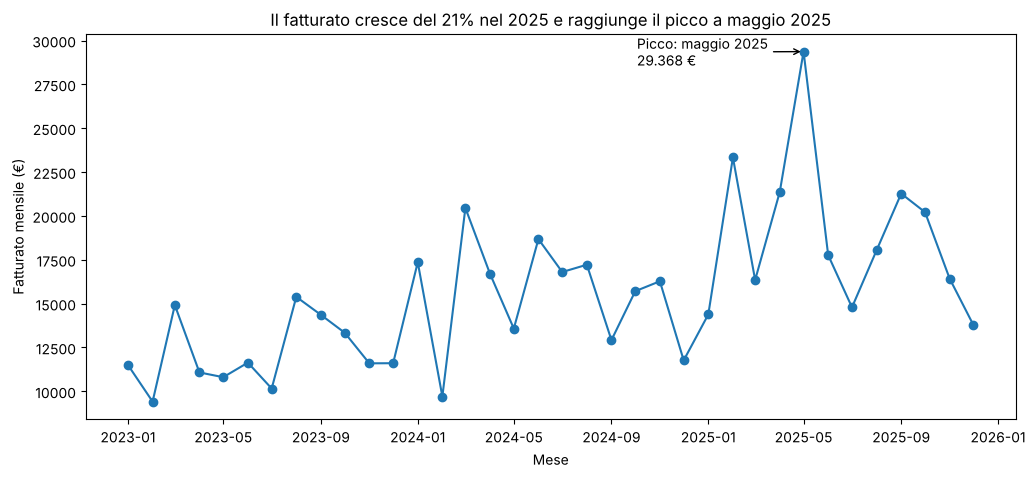

Anno
2023    145805.4
2024    187175.0
2025    227095.1
Name: SalesAmount, dtype: float64
Crescita 2025 su 2024: 21.3 %


In [19]:
# data del primo giorno di ogni mese, per l'asse x
mensile["Data"] = pd.to_datetime(mensile["Anno"].astype(str) + "-" + mensile["Mese"].astype(str) + "-01")

plt.figure(figsize=(12, 5))
plt.plot(mensile["Data"], mensile["Fatturato"], marker="o")

# annotazione sul mese di picco
plt.annotate("Picco: maggio 2025\n29.368 €",
             xy=(mensile.loc[riga_massimo, "Data"], fatturato_picco),
             xytext=(-120, -10), textcoords="offset points",
             arrowprops=dict(arrowstyle="->"))

plt.title("Il fatturato cresce del 21% nel 2025 e raggiunge il picco a maggio 2025")
plt.xlabel("Mese")
plt.ylabel("Fatturato mensile (€)")
plt.show()

# controllo del 21%
fatturato_anno = df.groupby("Anno")["SalesAmount"].sum()
print(fatturato_anno)
print("Crescita 2025 su 2024:", round((fatturato_anno[2025] / fatturato_anno[2024] - 1) * 100, 1), "%")

**Risposta 4.1**: il fatturato è passato da 145.805 € nel 2023 a 187.175 € nel 2024 e 227.095 € nel 2025, cioè **+21% nel 2025**. Il picco è a **maggio 2025** (29.368 €), molto sopra gli altri mesi. Da un mese all'altro però il fatturato sale e scende parecchio.

### Task 4.2 · Seaborn: boxplot e heatmap
**Domande di business**: 1) come sono distribuiti gli importi delle vendite nelle categorie? 2) quali variabili dei rivenditori sono collegate tra loro e al churn?

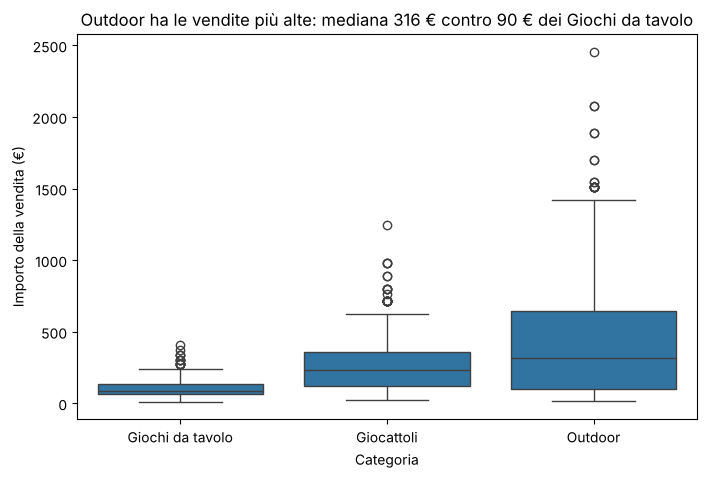

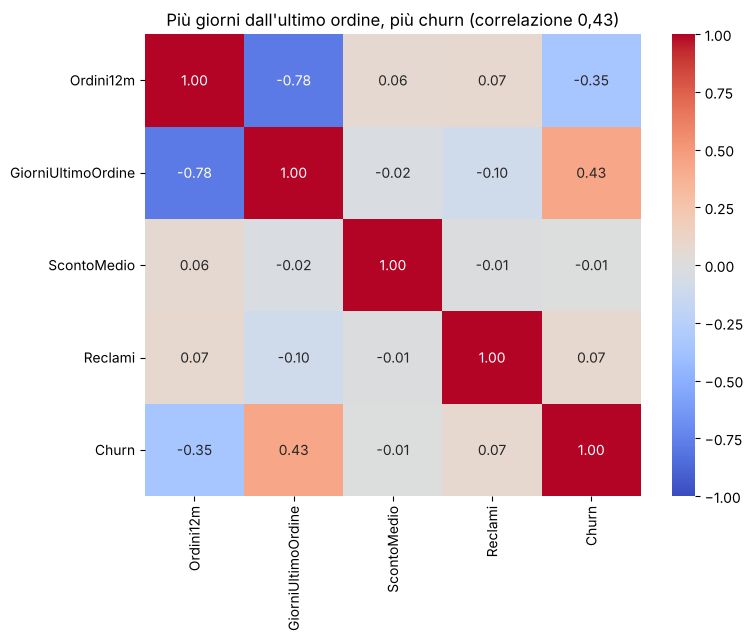

Category
Giocattoli          236.0
Giochi da tavolo     89.5
Outdoor             316.0
Name: SalesAmount, dtype: float64


In [20]:
# boxplot degli importi per categoria
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Category", y="SalesAmount")
plt.title("Outdoor ha le vendite più alte: mediana 316 € contro 90 € dei Giochi da tavolo")
plt.xlabel("Categoria")
plt.ylabel("Importo della vendita (€)")
plt.show()

# heatmap della correlazione tra le variabili numeriche di resellers (senza gli ID, che sono solo codici)
variabili = ["Ordini12m", "GiorniUltimoOrdine", "ScontoMedio", "Reclami", "Churn"]
correlazioni_resellers = resellers[variabili].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlazioni_resellers, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Più giorni dall'ultimo ordine, più churn (correlazione 0,43)")
plt.show()

print(df.groupby("Category")["SalesAmount"].median())

**Risposta 4.2**:
- **Boxplot**: le vendite di **Outdoor** sono le più alte (mediana 316 €) e quelle dei Giochi da tavolo le più basse (mediana 90 €). Nelle Outdoor ci sono anche alcune vendite molto alte (i punti sopra i baffi).
- **Heatmap**: la variabile più legata al churn è **`GiorniUltimoOrdine`** (correlazione 0,43, positiva: più giorni passano dall'ultimo ordine, più è probabile il churn). `Ordini12m` è legata al churn in negativo (-0,35) e molto a `GiorniUltimoOrdine` (-0,78). `ScontoMedio` e `Reclami` non c'entrano quasi niente con il churn.

### Task 4.3 · Plotly (opzionale): fatturato per stato
**Domanda di business**: quali stati portano più fatturato? Nel tooltip (passando il mouse) voglio vedere quantità totale e numero di transazioni.

In [21]:
per_stato = df.groupby("State").agg(
    Fatturato=("SalesAmount", "sum"),
    Quantita=("Quantity", "sum"),
    Transazioni=("SalesID", "count"),
)
per_stato = per_stato.sort_values("Fatturato", ascending=False).reset_index()

fig = px.bar(per_stato, x="State", y="Fatturato",
             hover_data=["Quantita", "Transazioni"],
             title="L'Austria è lo stato che fattura di più (74.426 €)")
fig.show()

per_stato

,State,Fatturato,Quantita,Transazioni
0,Austria,74426.4,1335.0,278
1,Norvegia,71802.4,1240.0,244
2,Germania,70867.6,1145.0,232
3,Svezia,69482.2,1144.0,230
4,Spagna,59227.8,1068.0,214
5,Italia,56601.6,908.0,184
6,Svizzera,55768.2,933.0,188
7,Francia,52994.9,877.0,171
8,Danimarca,48904.4,791.0,159


**Risposta 4.3**: lo stato che fattura di più è **Austria** (74.426 €), poi Norvegia (71.802 €) e Germania (70.868 €). Il più basso è Danimarca (48.904 €). Passando il mouse sulle barre si vedono quantità e transazioni.

### Definizione richiesta · quale grafico scegliere
- **Andamento nel tempo** → grafico a **linee** (fatturato mensile).
- **Confronto tra categorie** → **barre** (fatturato per stato).
- **Distribuzione** → **boxplot** (importi per categoria).
- **Relazione tra variabili** → **heatmap** di correlazione o **scatter** (correlazioni dei rivenditori).

**Criterio di completamento**: ✔ grafico a linee, boxplot e heatmap (più le barre Plotly) · ✔ dopo ogni grafico c'è la domanda di business e la risposta.

---
# Task 5 · Correlazione e regressione lineare

### Task 5.1 · Correlazioni
**Cosa chiede**: con `.corr()` calcolare la correlazione tra fatturato mensile, quantità mensile e numero di rivenditori attivi nel mese, e dire quale coppia è la più correlata.

Un rivenditore è "attivo" in un mese se ha almeno una vendita in quel mese.

In [22]:
dati_mensili = df.groupby(["Anno", "Mese"]).agg(
    Fatturato=("SalesAmount", "sum"),
    Quantita=("Quantity", "sum"),
    RivenditoriAttivi=("ResellerID", "nunique"),
)
dati_mensili = dati_mensili.reset_index()

# indice del mese: 1 = gennaio 2023, ..., 36 = dicembre 2025
dati_mensili["IndiceMese"] = range(1, len(dati_mensili) + 1)

correlazioni = dati_mensili[["Fatturato", "Quantita", "RivenditoriAttivi"]].corr()
correlazioni

,Fatturato,Quantita,RivenditoriAttivi
Fatturato,1.000000,0.867742,0.556200
Quantita,0.867742,1.000000,0.673118
RivenditoriAttivi,0.556200,0.673118,1.000000


**Risposta 5.1**: la coppia più correlata è **Fatturato e Quantità (0,87)**. Le altre: Quantità e Rivenditori attivi 0,67, Fatturato e Rivenditori attivi 0,56. Attenzione: una correlazione alta non vuol dire che una cosa causa l'altra.

### Task 5.2 · Regressione semplice e multipla
**Cosa chiede**: dopo `train_test_split(test_size=0.2, random_state=42)`, stimare con `LinearRegression` una regressione semplice (fatturato sull'indice del mese) e una multipla (indice del mese, quantità, rivenditori attivi).

In [23]:
X = dati_mensili[["IndiceMese", "Quantita", "RivenditoriAttivi"]]
y = dati_mensili["Fatturato"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Mesi nel train:", len(X_train), "| mesi nel test:", len(X_test))

# modello semplice: solo l'indice del mese
modello_semplice = LinearRegression()
modello_semplice.fit(X_train[["IndiceMese"]], y_train)

# modello multiplo: tutte e tre le variabili
modello_multiplo = LinearRegression()
modello_multiplo.fit(X_train, y_train)

Mesi nel train: 28 | mesi nel test: 8


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ -78.11, 85.31,-229.36]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['IndiceMese','Quantita','RivenditoriAttivi']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,6324
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


**Risposta 5.2**: con lo split 80/20 ho **28 mesi per il train e 8 per il test**. I due modelli sono stati addestrati sullo stesso train.

### Task 5.3 · `coef_`, `intercept_`, R² e previsione
**Cosa chiede**: riportare `coef_`, `intercept_` e R² su train e test per i due modelli; (opzionale) prevedere con il modello semplice il fatturato dei tre mesi dopo l'ultimo.

In [24]:
print("MODELLO SEMPLICE")
print("coef_:", modello_semplice.coef_)
print("intercept_:", modello_semplice.intercept_)
print("R2 train:", modello_semplice.score(X_train[["IndiceMese"]], y_train))
print("R2 test: ", modello_semplice.score(X_test[["IndiceMese"]], y_test))

print()
print("MODELLO MULTIPLO")
print("coef_:", modello_multiplo.coef_)
print("intercept_:", modello_multiplo.intercept_)
print("R2 train:", modello_multiplo.score(X_train, y_train))
print("R2 test: ", modello_multiplo.score(X_test, y_test))

# previsione dei prossimi 3 mesi (indici 37, 38, 39 = gennaio, febbraio, marzo 2026) con il modello semplice
mesi_futuri = pd.DataFrame({"IndiceMese": [37, 38, 39]})
previsioni = modello_semplice.predict(mesi_futuri)
print()
print("Previsioni gennaio, febbraio, marzo 2026:", previsioni)

MODELLO SEMPLICE
coef_: [303.57718604]
intercept_: 10602.52906483967
R2 train: 0.4771069064080533
R2 test:  -1.8790537398928593

MODELLO MULTIPLO
coef_: [ -78.10534205   85.30543512 -229.35501331]
intercept_: 6323.67262123109
R2 train: 0.8359739658323774
R2 test:  -0.4147571881471126

Previsioni gennaio, febbraio, marzo 2026: [21834.88494844 22138.46213448 22442.03932053]


**Risposta 5.3**:

| Modello | `coef_` | `intercept_` | R² train | R² test |
|---|---|---|---|---|
| Semplice | 303,58 | 10.602,53 | 0,477 | -1,879 |
| Multiplo | -78,11, 85,31, -229,36 | 6.323,67 | 0,836 | -0,415 |

- **Coefficiente dell'indice del mese** (modello semplice): il fatturato mensile sale in media di circa **304 € al mese**.
- **Previsioni** (modello semplice): gennaio 2026 **21.835 €**, febbraio 2026 **22.138 €**, marzo 2026 **22.442 €**.
- **Cosa ne penso**: l'R² sul test è **negativo** in tutti e due i modelli, cioè sul test funzionano peggio di una previsione fatta con la sola media. Il modello multiplo va meglio del semplice sia sul train sia sul test, ma sul test resta negativo e la differenza tra train e test è grande: si adatta troppo ai dati di allenamento. Il motivo è che i mesi sono solo 36 (8 nel test) e il fatturato cambia molto da un mese all'altro. Quindi le previsioni vanno prese con cautela.

### Definizione richiesta · R²
L'**R²** misura **quanta parte della variabilità del fatturato è spiegata dal modello**. Vale 1 se il modello spiega tutto, 0 se fa come la media; può anche essere negativo se fa peggio della media. Un R² o una correlazione alti **non dimostrano che una cosa causa l'altra**: dicono solo che due cose vanno insieme (magari per una terza causa, o per caso).

**Criterio di completamento**: ✔ tabella dei due modelli con coefficienti, R² train e R² test · ✔ tre valori previsti in € · ✔ coefficiente dell'indice del mese letto in € al mese.

---
# Task 6a · Classificazione del churn

### Task 6a.1 · X, y, split e scaler
**Cosa chiede**: X = `Ordini12m`, `GiorniUltimoOrdine`, `ScontoMedio`, `Reclami`; y = `Churn`; `train_test_split` con `stratify=y` e `StandardScaler` con il `fit` solo sul training.

Ho usato `test_size=0.2` e `random_state=42` come nel Task 5.

In [25]:
X_churn = resellers[["Ordini12m", "GiorniUltimoOrdine", "ScontoMedio", "Reclami"]]
y_churn = resellers["Churn"]

X_tr, X_te, y_tr, y_te = train_test_split(X_churn, y_churn, test_size=0.2, random_state=42, stratify=y_churn)

scaler = StandardScaler()
X_tr_s = scaler.fit_transform(X_tr)   # fit solo sul training
X_te_s = scaler.transform(X_te)       # sul test solo transform

print("Rivenditori in train:", len(X_tr), "| in test:", len(X_te))
print("Quota di churn nel train:", round(y_tr.mean(), 3))
print("Quota di churn nel test: ", round(y_te.mean(), 3))

Rivenditori in train: 240 | in test: 60
Quota di churn nel train: 0.238
Quota di churn nel test:  0.233


**Risposta 6a.1**: **240 rivenditori in train e 60 in test**. Con `stratify=y` la quota di churn è quasi uguale nei due gruppi (train 23,8%, test 23,3%). Lo scaler impara media e deviazione standard solo dal training, così il test non influenza l'addestramento.

### Task 6a.2 · Regressione logistica e matrici di confusione
**Cosa chiede**: addestrare `LogisticRegression`, ottenere `predict()` e `predict_proba()` e fare la matrice di confusione con soglia 0,5 e con soglia 0,3.

In [26]:
modello = LogisticRegression()
modello.fit(X_tr_s, y_tr)

previsioni_05 = modello.predict(X_te_s)               # predict() usa la soglia 0,5
probabilita = modello.predict_proba(X_te_s)[:, 1]     # probabilità di churn

# con soglia 0,3: churn se la probabilità è almeno 0,3
previsioni_03 = (probabilita >= 0.3).astype(int)

print("Matrice di confusione, soglia 0,5 (righe = reale, colonne = previsto):")
print(confusion_matrix(y_te, previsioni_05))
print()
print("Matrice di confusione, soglia 0,3:")
print(confusion_matrix(y_te, previsioni_03))

Matrice di confusione, soglia 0,5 (righe = reale, colonne = previsto):
[[42  4]
 [10  4]]

Matrice di confusione, soglia 0,3:
[[36 10]
 [ 4 10]]


**Risposta 6a.2**: nella matrice le righe sono il valore reale (0 = non churn, 1 = churn) e le colonne il previsto. Con soglia **0,5** il modello trova **4 rivenditori in churn su 14** (10 gli sfuggono). Con soglia **0,3** ne trova **10 su 14** (ne sfuggono 4), ma sbaglia di più sui sani: falsi allarmi 10 contro 4.

### Task 6a.3 · Accuracy, Precision, Recall e baseline
**Cosa chiede**: calcolare Accuracy, Precision e Recall per le due soglie e confrontare l'Accuracy con la baseline `Churn = 0` (dire sempre "nessun churn").

In [27]:
for soglia_nome, previsti in [("soglia 0,5", previsioni_05), ("soglia 0,3", previsioni_03)]:
    print(soglia_nome)
    print("  Accuracy: ", round(accuracy_score(y_te, previsti), 3))
    print("  Precision:", round(precision_score(y_te, previsti), 3))
    print("  Recall:   ", round(recall_score(y_te, previsti), 3))

# baseline: prevedo sempre Churn = 0
baseline = accuracy_score(y_te, [0] * len(y_te))
print()
print("Accuracy della baseline (sempre Churn = 0):", round(baseline, 3))

soglia 0,5
  Accuracy:  0.767
  Precision: 0.5
  Recall:    0.286
soglia 0,3
  Accuracy:  0.767
  Precision: 0.5
  Recall:    0.714

Accuracy della baseline (sempre Churn = 0): 0.767


**Risposta 6a.3** (sul test):

| Soglia | Accuracy | Precision | Recall |
|---|---|---|---|
| 0,5 | 0,767 | 0,500 | 0,286 |
| 0,3 | 0,767 | 0,500 | 0,714 |

La baseline ha Accuracy **0,767**, praticamente uguale a quella del modello: l'Accuracy da sola non dice molto, perché i rivenditori in churn sono pochi. Quello che cambia con la soglia è la **Recall**.

**Soglia scelta: 0,3.** L'Accuracy è uguale nei due casi, ma con 0,3 la Recall è molto più alta (0,714 contro 0,286). Nel churn un falso negativo (un rivenditore che se ne va e non lo avevo visto) costa più di un falso positivo (un rivenditore sano che contatto per niente), quindi preferisco la soglia con la Recall più alta.

### Task 6a.4 · Train e test: underfitting o overfitting?
**Cosa chiede**: confrontare Accuracy e Recall su train e test e dire se il modello è in underfitting, ha un buon adattamento o è in overfitting.

In [28]:
probabilita_train = modello.predict_proba(X_tr_s)[:, 1]
train_05 = (probabilita_train >= 0.5).astype(int)
train_03 = (probabilita_train >= 0.3).astype(int)

print("Soglia 0,3")
print("  Accuracy train:", round(accuracy_score(y_tr, train_03), 3), "| test:", round(accuracy_score(y_te, previsioni_03), 3))
print("  Recall   train:", round(recall_score(y_tr, train_03), 3), "| test:", round(recall_score(y_te, previsioni_03), 3))
print("Soglia 0,5")
print("  Accuracy train:", round(accuracy_score(y_tr, train_05), 3), "| test:", round(accuracy_score(y_te, previsioni_05), 3))
print("  Recall   train:", round(recall_score(y_tr, train_05), 3), "| test:", round(recall_score(y_te, previsioni_05), 3))

# (opzionale) AUC sul test
auc = roc_auc_score(y_te, probabilita)
print()
print("AUC sul test:", round(auc, 3))

Soglia 0,3
  Accuracy train: 0.742 | test: 0.767
  Recall   train: 0.754 | test: 0.714
Soglia 0,5
  Accuracy train: 0.775 | test: 0.767
  Recall   train: 0.316 | test: 0.286

AUC sul test: 0.761


**Risposta 6a.4**: con la soglia 0,3 l'Accuracy è 0,742 sul train e 0,767 sul test; la Recall è 0,754 sul train e 0,714 sul test.

**Diagnosi: buon adattamento, niente overfitting.** I valori di train e test sono vicini, quindi il modello non ha "imparato a memoria" il train. Non è però un modello forte: l'Accuracy è vicina alla baseline e l'AUC sul test è **0,76** (0,5 = a caso, 1 = perfetto), quindi è un modello discreto ma non ottimo.

### Definizione richiesta · apprendimento supervisionato e non supervisionato
- **Supervisionato**: i dati hanno già la risposta giusta (l'etichetta) e il modello impara a prevederla. *Esempio nello scenario*: prevedere il `Churn` dei rivenditori (Task 6a).
- **Non supervisionato**: i dati non hanno etichetta e si cercano gruppi o schemi nascosti. *Esempio nello scenario*: dividere i rivenditori in segmenti con K-Means (Task 6b).

**Criterio di completamento**: ✔ tabella delle metriche per le due soglie · ✔ soglia scelta e motivata (0,3) · ✔ diagnosi train/test con i valori · ✔ AUC calcolata.

---
# Task 6b · Segmentazione dei rivenditori con K-Means

### Task 6b.1 · Fatturato per rivenditore e inerzia
**Cosa chiede**: calcolare il fatturato totale per rivenditore da `sales` con `groupby()`, standardizzare `Ordini12m`, `GiorniUltimoOrdine` e fatturato, e calcolare `inertia_` per k da 1 a 10 con `KMeans(n_init=10, random_state=42)`.

Alcuni rivenditori non hanno vendite: per loro il fatturato è 0.

In [29]:
# fatturato totale per rivenditore
fatturato_rivenditori = sales_pulito.groupby("ResellerID")["SalesAmount"].sum()
fatturato_rivenditori = fatturato_rivenditori.rename("Fatturato")

clienti = resellers.merge(fatturato_rivenditori, on="ResellerID", how="left")
senza_vendite = clienti["Fatturato"].isna().sum()
clienti["Fatturato"] = clienti["Fatturato"].fillna(0)
print("Rivenditori senza vendite:", senza_vendite)

# standardizzo le tre variabili
X_cluster = StandardScaler().fit_transform(clienti[["Ordini12m", "GiorniUltimoOrdine", "Fatturato"]])

# inerzia per k da 1 a 10
inerzie = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X_cluster)
    inerzie.append(km.inertia_)

print(inerzie)

Rivenditori senza vendite: 4


[899.9999999999998, 433.72750333980525, 319.2192330997629, 257.17481925478853, 225.59117387777565, 198.57635307821306, 180.65545834251571, 164.76848498606597, 149.72101679837468, 137.02826424795938]


**Risposta 6b.1**: **4 rivenditori** su 300 non hanno vendite (fatturato 0). Le variabili le standardizzo perché K-Means usa le distanze e il fatturato, con numeri molto più grandi, comanderebbe su tutto. L'inerzia scende da 900,0 (k = 1) a 137,0 (k = 10).

### Task 6b.2 · Metodo del gomito e cluster
**Cosa chiede**: scegliere k con il metodo del gomito e assegnare i cluster con `fit_predict()` in una nuova colonna.

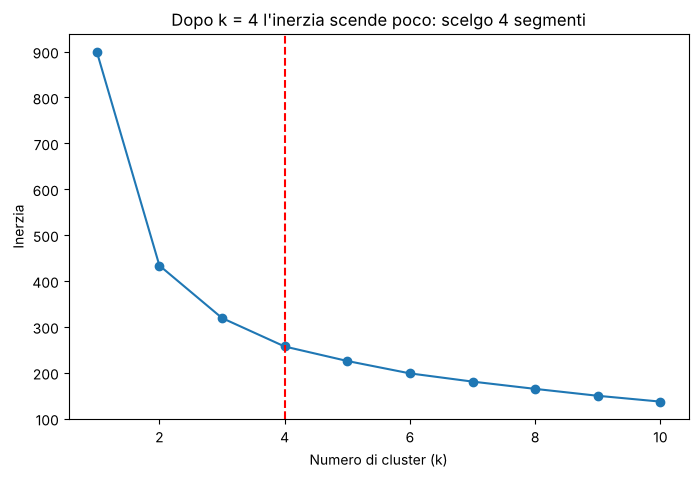

Cluster
2    83
0    79
3    74
1    64
Name: count, dtype: int64


In [30]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inerzie, marker="o")
plt.axvline(4, color="red", linestyle="--")
plt.title("Dopo k = 4 l'inerzia scende poco: scelgo 4 segmenti")
plt.xlabel("Numero di cluster (k)")
plt.ylabel("Inerzia")
plt.show()

# assegno i cluster con k = 4
km4 = KMeans(n_clusters=4, n_init=10, random_state=42)
clienti["Cluster"] = km4.fit_predict(X_cluster)

print(clienti["Cluster"].value_counts())

**Risposta 6b.2**: scelgo **k = 4**. Fino a 3-4 cluster l'inerzia scende molto; dopo il 4 ogni cluster in più la fa scendere sempre meno, e la curva si "piega" come un gomito. Con 4 segmenti inoltre i gruppi si spiegano bene (lo vediamo qui sotto). I cluster sono nella colonna `Cluster`.

### Task 6b.3 · Profili dei cluster e churn
**Cosa chiede**: descrivere i cluster con `groupby()` sulle variabili originali, dare un nome a ognuno e calcolare la quota di churn per cluster.

In [31]:
profili = clienti.groupby("Cluster").agg(
    Rivenditori=("ResellerID", "count"),
    Ordini12m=("Ordini12m", "mean"),
    GiorniUltimoOrdine=("GiorniUltimoOrdine", "mean"),
    Fatturato=("Fatturato", "mean"),
    QuotaChurn=("Churn", "mean"),
)
profili = profili.round(2)

# nomi dei cluster, scelti guardando la tabella qui sotto
# (con random_state=42 i numeri dei cluster sono sempre questi)
nomi = {
    0: "In raffreddamento",
    1: "Top rivenditori",
    2: "Regolari",
    3: "A rischio",
}
profili["Nome"] = profili.index.map(nomi)

profili

,Rivenditori,Ordini12m,GiorniUltimoOrdine,Fatturato,QuotaChurn,Nome
Cluster,,,,,,
0,79,14.48,124.19,2019.67,0.28,In raffreddamento
1,64,22.20,37.56,3490.99,0.06,Top rivenditori
2,83,19.94,44.51,1422.53,0.08,Regolari
3,74,11.00,151.19,797.68,0.51,A rischio


**Risposta 6b.3**:

| Cluster | Nome | Rivenditori | Ordini 12m | Giorni dall'ultimo ordine | Fatturato medio | Quota di churn |
|---|---|---|---|---|---|---|
| 0 | In raffreddamento | 79 | 14,5 | 124 | 2.020 € | 28% |
| 1 | Top rivenditori | 64 | 22,2 | 38 | 3.491 € | 6% |
| 2 | Regolari | 83 | 19,9 | 45 | 1.423 € | 8% |
| 3 | A rischio | 74 | 11,0 | 151 | 798 € | 51% |

Il **segmento con il churn più alto è "A rischio"** (cluster 3): 51% di churn, pochi ordini (11,0), tanti giorni dall'ultimo ordine (151) e fatturato basso. Il churn più basso è nei "Top rivenditori" (6%). Quindi il churn cresce quando gli ordini calano e passa più tempo dall'ultimo ordine, in linea con la heatmap del Task 4.2.

### Definizione richiesta · centroide, inerzia e perché K-Means non ha `y` né train/test
- **Centroide**: il "centro" di un cluster, cioè la media dei punti che ne fanno parte.
- **Inerzia**: la somma delle distanze al quadrato tra ogni punto e il centroide del suo cluster. Più è bassa, più i gruppi sono compatti. Scende sempre quando aumenta k, per questo si cerca il gomito.
- **Perché non serve `y`**: K-Means è non supervisionato, non deve prevedere nessuna risposta, cerca solo gruppi simili. **Perché non serve il train/test**: non c'è niente da prevedere su dati nuovi, quindi non c'è un test da fare. Il churn lo uso solo alla fine, per confrontare i segmenti.

**Criterio di completamento**: ✔ grafico del gomito con k scelto (k = 4) · ✔ tabella dei profili con nome e quota di churn · ✔ segmento con il churn più alto: **A rischio**.

---
# Task 7 · Debugging e refactoring
Per ogni caso scrivo: l'errore originale, la causa, il prompt che ho usato con l'assistente AI (Claude) e la versione corretta, che ho provato eseguendola qui nel notebook.

### Caso 1 · Media del fatturato
**Codice originale:**
```python
totale = 0
for v in sales["SalesAmount"]:
    totale += v
media = totale / len(sales)
```
**Errore**: non esce un errore, ma il risultato è `nan`.

**Causa**: in `SalesAmount` ci sono valori mancanti (NaN). Appena il ciclo ne incontra uno, il totale diventa NaN. Inoltre `len(sales)` conta anche le righe senza importo, quindi il divisore sarebbe sbagliato comunque.

**Prompt usato**: *«Ho questo codice che calcola la media di SalesAmount con un ciclo for ma mi dà nan. sales è un DataFrame con dei valori mancanti. Mi spieghi cosa sbaglio e come lo correggo senza usare .mean()?»*

**Versione corretta:** salto i NaN e divido per il numero di importi veri.

In [32]:
# codice originale: il risultato è nan
totale = 0
for v in sales["SalesAmount"]:
    totale += v
print("Media con il codice originale:", totale / len(sales))

# versione corretta
totale = 0
quanti = 0
for v in sales["SalesAmount"]:
    if not math.isnan(v):
        totale += v
        quanti += 1
media = totale / quanti

print("Media corretta:", round(media, 2))
print("Controllo con .mean():", round(sales["SalesAmount"].mean(), 2))

Media con il codice originale: nan
Media corretta: 294.78
Controllo con .mean(): 294.78


**Esito Caso 1**: la versione corretta dà **294,78 €** e coincide con `.mean()`.

### Caso 2 · Preparazione del modello
**Codice originale:**
```python
scaler = StandardScaler()
X_s = scaler.fit_transform(X)
X_train, X_test, y_train, y_test = \
    train_test_split(X_s, y)
```
**Errore**: non esce nessun errore, ma il metodo è sbagliato (si chiama *data leakage*).

**Causa**: lo scaler fa il `fit` su **tutti** i dati prima di dividere in train e test. Così media e deviazione standard usano anche i dati del test, e il test non è più "nuovo". Le metriche vengono troppo belle. In più manca `random_state`, quindi lo split cambia a ogni esecuzione.

**Prompt usato**: *«Questo codice standardizza X con StandardScaler e poi fa train_test_split. Funziona, ma mi hanno detto che c'è un errore di metodo. Qual è e come lo correggo?»*

**Versione corretta:** prima divido, poi faccio il `fit` dello scaler solo sul train.

In [33]:
X = resellers[["Ordini12m", "GiorniUltimoOrdine", "ScontoMedio", "Reclami"]]
y = resellers["Churn"]

# prima lo split (con random_state), poi lo scaler
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # fit solo sul train
X_test_s = scaler.transform(X_test)         # sul test solo transform

print("Medie nel train dopo lo scaler (circa 0):", X_train_s.mean(axis=0).round(2))
print("Medie nel test dopo lo scaler (non 0, ed è giusto):", X_test_s.mean(axis=0).round(2))

Medie nel train dopo lo scaler (circa 0): [ 0. -0. -0.  0.]
Medie nel test dopo lo scaler (non 0, ed è giusto): [-0.17  0.07 -0.27 -0.06]


**Esito Caso 2**: nel train le medie sono circa 0 (lo scaler ha imparato da lì), nel test no: il test è stato solo trasformato, senza che lo scaler lo "vedesse" prima.

### Caso 3 · Filtro vendite Bikes
**Codice originale:**
```python
alte = df[df["SalesAmount"] > 500 and
          df["Category"] == "Bikes"]
print(alte.shape)
```
**Errore**: `ValueError: The truth value of a Series is ambiguous.`

**Causa**: `and` funziona con singoli True/False, non con colonne intere. In Pandas per mettere insieme due condizioni si usa `&` (AND) e ogni condizione va tra parentesi.

**Prompt usato**: *«Ho questo filtro su un DataFrame: df[df["SalesAmount"] > 500 and df["Category"] == "Bikes"] e mi dà ValueError "The truth value of a Series is ambiguous". Cosa sbaglio?»*

**Versione corretta:** nel nostro dataset la categoria "Bikes" non esiste (ci sono Outdoor, Giocattoli e Giochi da tavolo), quindi con "Bikes" escono 0 righe. Come prova lo faccio anche con "Outdoor", dove ci sono le biciclette.

In [34]:
alte = df[(df["SalesAmount"] > 500) & (df["Category"] == "Bikes")]
print("Con Bikes:", alte.shape)
print("Categorie presenti:", df["Category"].unique())

alte_outdoor = df[(df["SalesAmount"] > 500) & (df["Category"] == "Outdoor")]
print("Con Outdoor:", alte_outdoor.shape)

Con Bikes: (0, 16)
Categorie presenti: <StringArray>
['Giochi da tavolo', 'Giocattoli', 'Outdoor']
Length: 3, dtype: str
Con Outdoor: (285, 16)


**Esito Caso 3**: la versione corretta funziona senza errori. Con "Bikes" restituisce 0 righe (la categoria non esiste), con "Outdoor" trova **285 vendite** sopra i 500 €.

### Caso 4 · Funzione di report
**Codice originale:**
```python
def f(d, x):
    return d[d.iloc[:, 3] > x]\
        .iloc[:, 6].sum()
```
**Errore**: non esce un errore, ma è scritto male: nomi senza significato (`f`, `d`, `x`), nessuna spiegazione e colonne scelte **per posizione** (`iloc[:, 3]` e `iloc[:, 6]`). Se cambia l'ordine delle colonne il risultato cambia senza avvisare e nessuno capisce cosa calcola.

**Causa**: nomi non chiari, niente docstring e colonne scelte con il numero invece che con il nome.

**Prompt usato**: *«Mi sistemi questa funzione? Non si capisce cosa fa. Voglio nomi chiari per funzione e parametri, le colonne scelte per nome e non per posizione, e una docstring. Nel mio DataFrame la colonna 3 è ResellerID e la 6 è SalesAmount: il risultato deve restare lo stesso.»*

**Versione corretta:** nomi chiari, colonne per nome e docstring.

In [35]:
# funzione originale (la tengo solo per confrontare il risultato)
def f(d, x):
    return d[d.iloc[:, 3] > x].iloc[:, 6].sum()

# versione corretta
def somma_importi_sopra_soglia(tabella, soglia, colonna_filtro="Quantity", colonna_importo="SalesAmount"):
    """Somma gli importi delle righe in cui colonna_filtro è maggiore di soglia.

    tabella: DataFrame delle vendite
    soglia: valore che colonna_filtro deve superare
    colonna_filtro: colonna su cui fare il filtro
    colonna_importo: colonna da sommare
    """
    righe = tabella[tabella[colonna_filtro] > soglia]
    return righe[colonna_importo].sum()

print("Colonna 3:", df.columns[3], "| colonna 6:", df.columns[6])
vecchio = f(df, 100)
nuovo = somma_importi_sopra_soglia(df, 100, colonna_filtro="ResellerID", colonna_importo="SalesAmount")
print("Risultato originale:", round(vecchio, 2))
print("Risultato nuovo:    ", round(nuovo, 2))

# esempio con i valori standard: importi delle vendite con più di 5 pezzi
print("Fatturato delle vendite con Quantity > 5:", round(somma_importi_sopra_soglia(df, 5), 2))

Colonna 3: ResellerID | colonna 6: SalesAmount
Risultato originale: 379895.9
Risultato nuovo:     379895.9
Fatturato delle vendite con Quantity > 5: 275260.4


**Esito Caso 4**: la nuova funzione ha nomi chiari, usa i nomi delle colonne e ha la docstring. Con `colonna_filtro="ResellerID"` dà lo stesso risultato della vecchia `f()` (379.895,90 €).

### Versioning su GitHub
Il notebook e i file di dati (`products.csv`, `regions.xlsx`, `sales.json`, `resellers.csv`) vanno su un repository GitHub insieme a un `README.md` con scenario, task e istruzioni, con almeno tre commit descrittivi.

**Criterio di completamento Task 7**: ✔ quattro celle corrette ed eseguite senza errori · ✔ Caso 4 con nomi chiari e docstring · ✔ repository GitHub con notebook, dati, README e tre commit.